In [2]:
# Run once in a separate notebook cell if these packages are missing:
%pip install pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [11]:
import pandas as panda
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.impute import SimpleImputer

import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df=panda.read_csv('sentimentdataset.csv')
print(df)

     Unnamed: 0.1  Unnamed: 0  \
0               0           0   
1               1           1   
2               2           2   
3               3           3   
4               4           4   
..            ...         ...   
727           728         732   
728           729         733   
729           730         734   
730           731         735   
731           732         736   

                                                  Text    Sentiment  \
0     Enjoying a beautiful day at the park!        ...   Positive     
1     Traffic was terrible this morning.           ...   Negative     
2     Just finished an amazing workout! 💪          ...   Positive     
3     Excited about the upcoming weekend getaway!  ...   Positive     
4     Trying out a new recipe for dinner tonight.  ...   Neutral      
..                                                 ...          ...   
727  Collaborating on a science project that receiv...       Happy    
728  Attending a surprise birthday 

In [14]:
df['Timestamp'] = panda.to_datetime(df['Timestamp'])
#df['Time_of_Day'] = df['Timestamp'].dt.hour.apply(lambda x: 'DAY' if 6 <= x < 18 else 'NIGHT')

#Converting Time_of_Day into binary - 0 is Day [06:00hrs to 18:00hrs] and 1 is Night [18:00hrs to 06:00hrs]
df['Time_of_Day'] = df['Timestamp'].dt.hour.apply(lambda x: 0 if 6 <= x < 18 else 1)

In [15]:
lab_enc = LabelEncoder()
df['Hashtags'] = lab_enc.fit_transform(df['Hashtags'])

In [16]:
scale = MinMaxScaler()
df[['Likes', 'Retweets']] = scale.fit_transform(df[['Likes', 'Retweets']])

In [17]:
distinct_sentiments = df['Sentiment'].unique()
print("Distinct Sentiments:", distinct_sentiments)

Distinct Sentiments: <StringArray>
[   ' Positive  ',    ' Negative  ',    ' Neutral   ', ' Anger        ',
 ' Fear         ', ' Sadness      ', ' Disgust      ', ' Happiness    ',
 ' Joy          ', ' Love         ',
 ...
      ' Disgust ',       ' Relief ',     ' Positive ',  ' Embarrassed ',
  ' Mischievous ',          ' Sad ',         ' Hate ',          ' Bad ',
      ' Neutral ',        ' Happy ']
Length: 279, dtype: str


In [18]:
sent_mapping = {
    ' Positive  ': 0.8,
    ' Negative  ': 0.2,
    ' Neutral   ': 0.5,
    ' Anger        ': 0.1,
    ' Fear         ': 0.3,
    ' Sadness      ': 0.2,
    ' Disgust      ': 0.1,
    ' Happiness    ': 0.8,
    ' Joy          ': 0.8,
    ' Love         ': 0.9,
    ' Amusement    ': 0.7,
    ' Enjoyment    ': 0.7,
    ' Admiration   ': 0.8,
    ' Affection    ': 0.8,
    ' Awe          ': 0.8,
    ' Disappointed ': 0.3,
    ' Surprise     ': 0.7,
    ' Acceptance   ': 0.7,
    ' Adoration    ': 0.8,
    ' Anticipation ': 0.7,
    ' Bitter       ': 0.3,
    ' Calmness     ': 0.6,
    ' Confusion    ': 0.5,
    ' Excitement   ': 0.7,
    ' Kind         ': 0.7,
    ' Pride        ': 0.8,
    ' Shame        ': 0.2,
    ' Elation       ': 0.8,
    ' Euphoria      ': 0.9,
    ' Contentment   ': 0.8,
    ' Serenity      ': 0.8,
    ' Gratitude     ': 0.8,
    ' Hope          ': 0.7,
    ' Empowerment   ': 0.7,
    ' Compassion    ': 0.8,
    ' Tenderness    ': 0.8,
    ' Arousal       ': 0.7,
    ' Enthusiasm    ': 0.7,
    ' Fulfillment  ': 0.7,
    ' Reverence     ': 0.8,
    ' Zest ': 0.7,
    ' Contentment ': 0.8,
    ' Hopeful ': 0.7,
    ' Proud ': 0.8,
    ' Grateful ': 0.8,
    ' Empathetic ': 0.8,
    ' Compassionate ': 0.8,
    ' Playful ': 0.7,
    ' Free-spirited ': 0.7,
    ' Inspired ': 0.7,
    ' Confident ': 0.7,
    ' Curiosity ': 0.7,
    ' Ambivalence ': 0.5,
    ' Despair ': 0.2,
    ' Bitterness ': 0.3,
    ' Yearning ': 0.3,
    ' Fearful ': 0.3,
    ' Apprehensive ': 0.4,
    ' Overwhelmed ': 0.2,
    ' Jealous ': 0.3,
    ' Devastated ': 0.2,
    ' Frustrated ': 0.3,
    ' Envious ': 0.3,
    ' Dismissive ': 0.3,
    ' Awe           ': 0.8,
    ' Determination ': 0.7,
    ' Nostalgia      ': 0.6,
    ' Thrill         ': 0.7,
    ' Calmness       ': 0.6,
    ' Overwhelmed    ': 0.2,
    ' Gratitude  ': 0.8,
    ' Bittersweet ': 0.5,
    ' Curiosity     ': 0.7,
    ' Admiration    ': 0.8,
    ' Overjoyed     ': 0.8,
    ' Inspiration   ': 0.7,
    ' Motivation    ': 0.7,
    ' Amusement     ': 0.7,
    ' Contemplation ': 0.6,
    ' JoyfulReunion ': 0.8,
    ' Excitement    ': 0.7,
    ' Satisfaction  ': 0.8,
    ' Blessed       ': 0.8,
    ' Anticipation  ': 0.7,
    ' Reflection    ': 0.7,
    ' Nostalgia     ': 0.6,
    ' Appreciation  ': 0.8,
    ' Confidence    ': 0.7,
    ' Surprise      ': 0.7,
    ' Accomplishment': 0.8,
    ' Wonderment    ': 0.7,
    ' Optimism      ': 0.7,
    ' Pride         ': 0.8,
    ' Happiness     ': 0.8,
    ' Curiosity   ': 0.7,
    ' Enchantment   ': 0.8,
    ' Intrigue      ': 0.6,
    ' PlayfulJoy    ': 0.8,
    ' Mindfulness   ': 0.7,
    ' DreamChaser   ': 0.7,
    ' Elegance ': 0.7,
    ' Whimsy        ': 0.7,
    ' Pensive ': 0.5,
    ' Thrill       ': 0.7,
    ' Harmony    ': 0.7,
    ' Creativity   ': 0.7,
    ' Radiance    ': 0.7,
    ' Wonder     ': 0.7,
    ' Rejuvenation ': 0.7,
    ' Inspiration ': 0.7,
    ' Coziness     ': 0.7,
    ' Gratitude  ': 0.8,
    ' Adventure ': 0.7,
    ' Euphoria   ': 0.9,
    ' Awe    ': 0.8,
    ' Melodic       ': 0.7,
    ' FestiveJoy    ': 0.8,
    ' InnerJourney  ': 0.7,
    ' Freedom       ': 0.7,
    ' Dazzle        ': 0.8,
    ' Adrenaline     ': 0.7,
    ' Harmony       ': 0.7,
    ' ArtisticBurst ': 0.7,
    ' Radiance      ': 0.7,
    ' Wonder       ': 0.7,
    ' Inspiration  ': 0.7,
    ' CulinaryOdyssey ': 0.7,
    ' Euphoria     ': 0.9,
    ' Curiosity  ': 0.7,
    ' Resilience   ': 0.7,
    ' Immersion ': 0.7,
    ' Nostalgia ': 0.6,
    ' Spark        ': 0.6,
    ' Marvel       ': 0.7,
    ' Serenity   ': 0.8,
    ' Heartbreak    ': 0.2,
    ' Loneliness    ': 0.2,
    ' Grief      ': 0.2,
    ' Despair   ': 0.2,
    ' Betrayal      ': 0.2,
    ' Suffering ': 0.2,
    ' EmotionalStorm ': 0.3,
    ' Regret        ': 0.2,
    ' Isolation ': 0.2,
    ' Disappointment ': 0.2,
    ' LostLove ': 0.2,
    ' Melancholy ': 0.2,
    ' Exhaustion ': 0.3,
    ' Sorrow      ': 0.2,
    ' Darkness     ': 0.1,
    ' Desperation ': 0.2,
    ' Ruins      ': 0.1,
    ' Desolation ': 0.2,
    ' Grief ': 0.2,
    ' Heartbreak ': 0.2,
    ' Betrayal ': 0.2,
    ' Resilience ': 0.7,
    ' Sorrow ': 0.2,
    ' Loss ': 0.2,
    ' Heartache ': 0.2,
    ' Solitude ': 0.2,
    ' Happy ': 0.8,
    ' Embarrassed ': 0.3,
    ' Mischievous ': 0.7,
    ' Sad ': 0.2,
    ' Hate ': 0.1,
    ' Bad ': 0.1,
    ' Neutral ': 0.5
}
#print(df['Sentiment'])
df['Sentiment'] = df['Sentiment'].map(sent_mapping)
print(df['Sentiment'])


0      0.8
1      0.2
2      0.8
3      0.8
4      0.5
      ... 
727    0.8
728    0.8
729    0.8
730    0.8
731    0.8
Name: Sentiment, Length: 732, dtype: float64


In [19]:
weights = {'Sentiment': 0.4, 'Likes': 0.3, 'Retweets': 0.3}
df['Combined_User_Engagement_Score'] = (df['Sentiment']* weights['Sentiment']) + (df['Likes']* weights['Likes']) + (df['Retweets']* weights['Retweets'])

In [20]:
df.drop(['Unnamed: 0', 'Text', 'Timestamp', 'User','Platform', 'Country', 'Year', 'Month', 'Day', 'Hour'], axis=1, inplace=True)


In [21]:
X = df.drop(['Time_of_Day'], axis=1)
y = df['Time_of_Day']
print(df)
print(X)
print(y)

     Unnamed: 0.1  Sentiment  Hashtags  Retweets     Likes  Time_of_Day  \
0               0        0.8       491  0.285714  0.285714            0   
1               1        0.2       674  0.000000  0.000000            0   
2               2        0.8       309  0.428571  0.428571            0   
3               3        0.8       677  0.085714  0.071429            1   
4               4        0.5       158  0.200000  0.214286            1   
..            ...        ...       ...       ...       ...          ...   
727           728        0.8       600  0.428571  0.414286            1   
728           729        0.8       647  0.571429  0.542857            0   
729           730        0.8       128  0.485714  0.457143            0   
730           731        0.8       173  0.457143  0.471429            1   
731           732        0.8       682  0.542857  0.528571            0   

     Combined_User_Engagement_Score  
0                          0.491429  
1                      

In [22]:
# Handle missing values with an imputer
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)
X = panda.DataFrame(X_imputed, columns=X.columns)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
model = RandomForestClassifier()
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

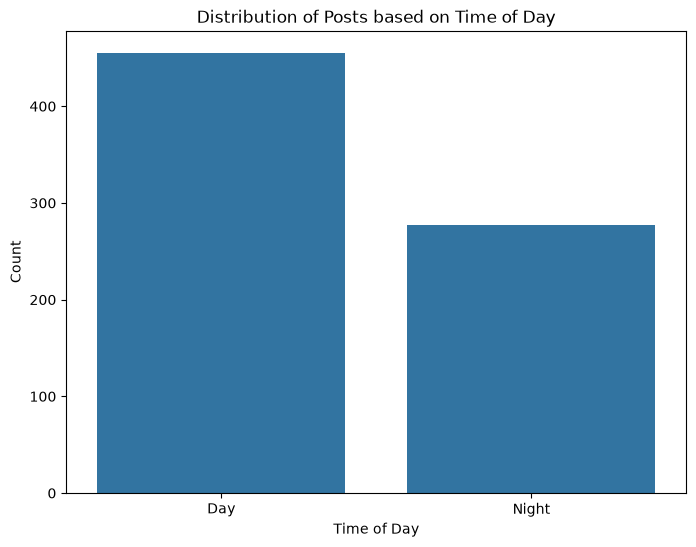

In [25]:
plt.figure(figsize=(8,6))
time_of_day_decoded=['Day','Night'] #Day is at 0th index and Night is at index 1
sns.countplot(data=df,x='Time_of_Day')
plt.title('Distribution of Posts based on Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Count')

#tick the locations [0,1] on x - axis and assign labels accordingly
plt.xticks([0,1], time_of_day_decoded)
plt.show()

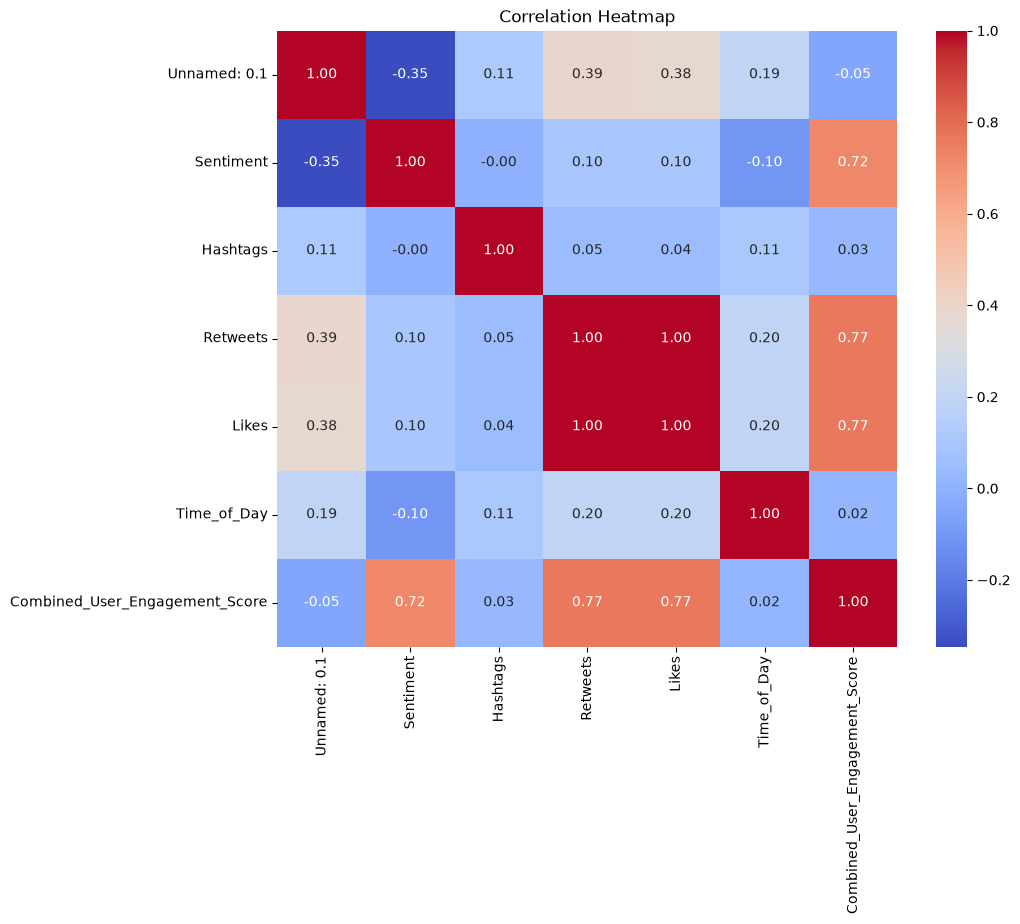

In [26]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

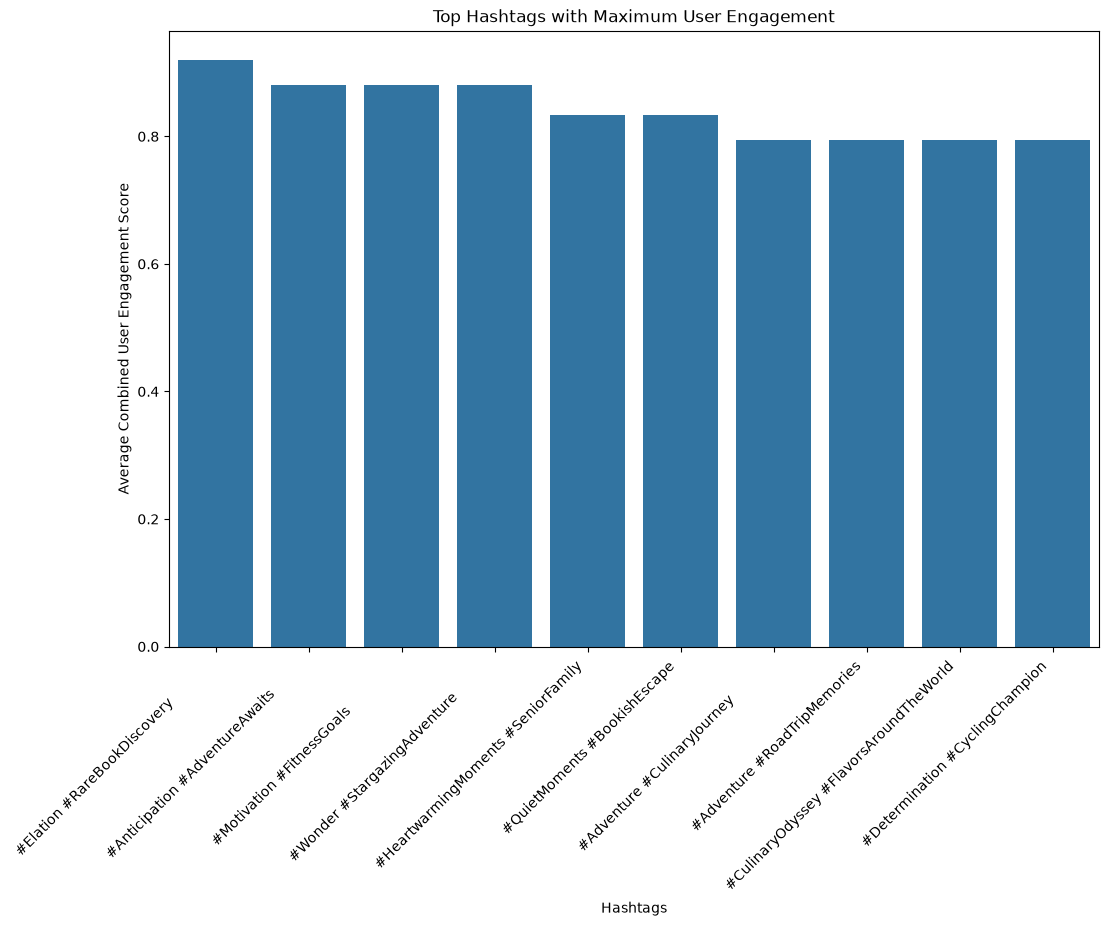

In [27]:
plt.figure(figsize=(12,8))
max_engagement_hashtags=df.groupby('Hashtags')['Combined_User_Engagement_Score'].mean().nlargest(10)

decoded_hash=lab_enc.inverse_transform(max_engagement_hashtags.index)

sns.barplot(x=decoded_hash, y=max_engagement_hashtags.values)
plt.title('Top Hashtags with Maximum User Engagement')
plt.xlabel('Hashtags')
plt.ylabel('Average Combined User Engagement Score')
plt.xticks(rotation=45, ha='right')
plt.show()